# (一) Beta分布参数估计

               Study            Seniority    N   mean     sd  alpha   beta
0  Carty & Lieberman       Senior Secured  115 0.5380 0.2686 1.3155 1.1297
1  Carty & Lieberman     Senior Unsecured  278 0.5113 0.2545 1.4612 1.3966
2  Carty & Lieberman  Senior Subordinated  196 0.3852 0.2381 1.2239 1.9534
3  Carty & Lieberman         Subordinated  226 0.3274 0.2018 1.4430 2.9645
4  Carty & Lieberman  Junior Subordinated    9 0.1709 0.1090 1.8673 9.0588
5   Altman & Kishore       Senior Secured   85 0.5789 0.2299 2.0911 1.5211
6   Altman & Kishore     Senior Unsecured  221 0.4765 0.2671 1.1896 1.3069
7   Altman & Kishore  Senior Subordinated  177 0.3438 0.2508 0.8893 1.6973
8   Altman & Kishore         Subordinated  214 0.3134 0.2242 1.0282 2.2526


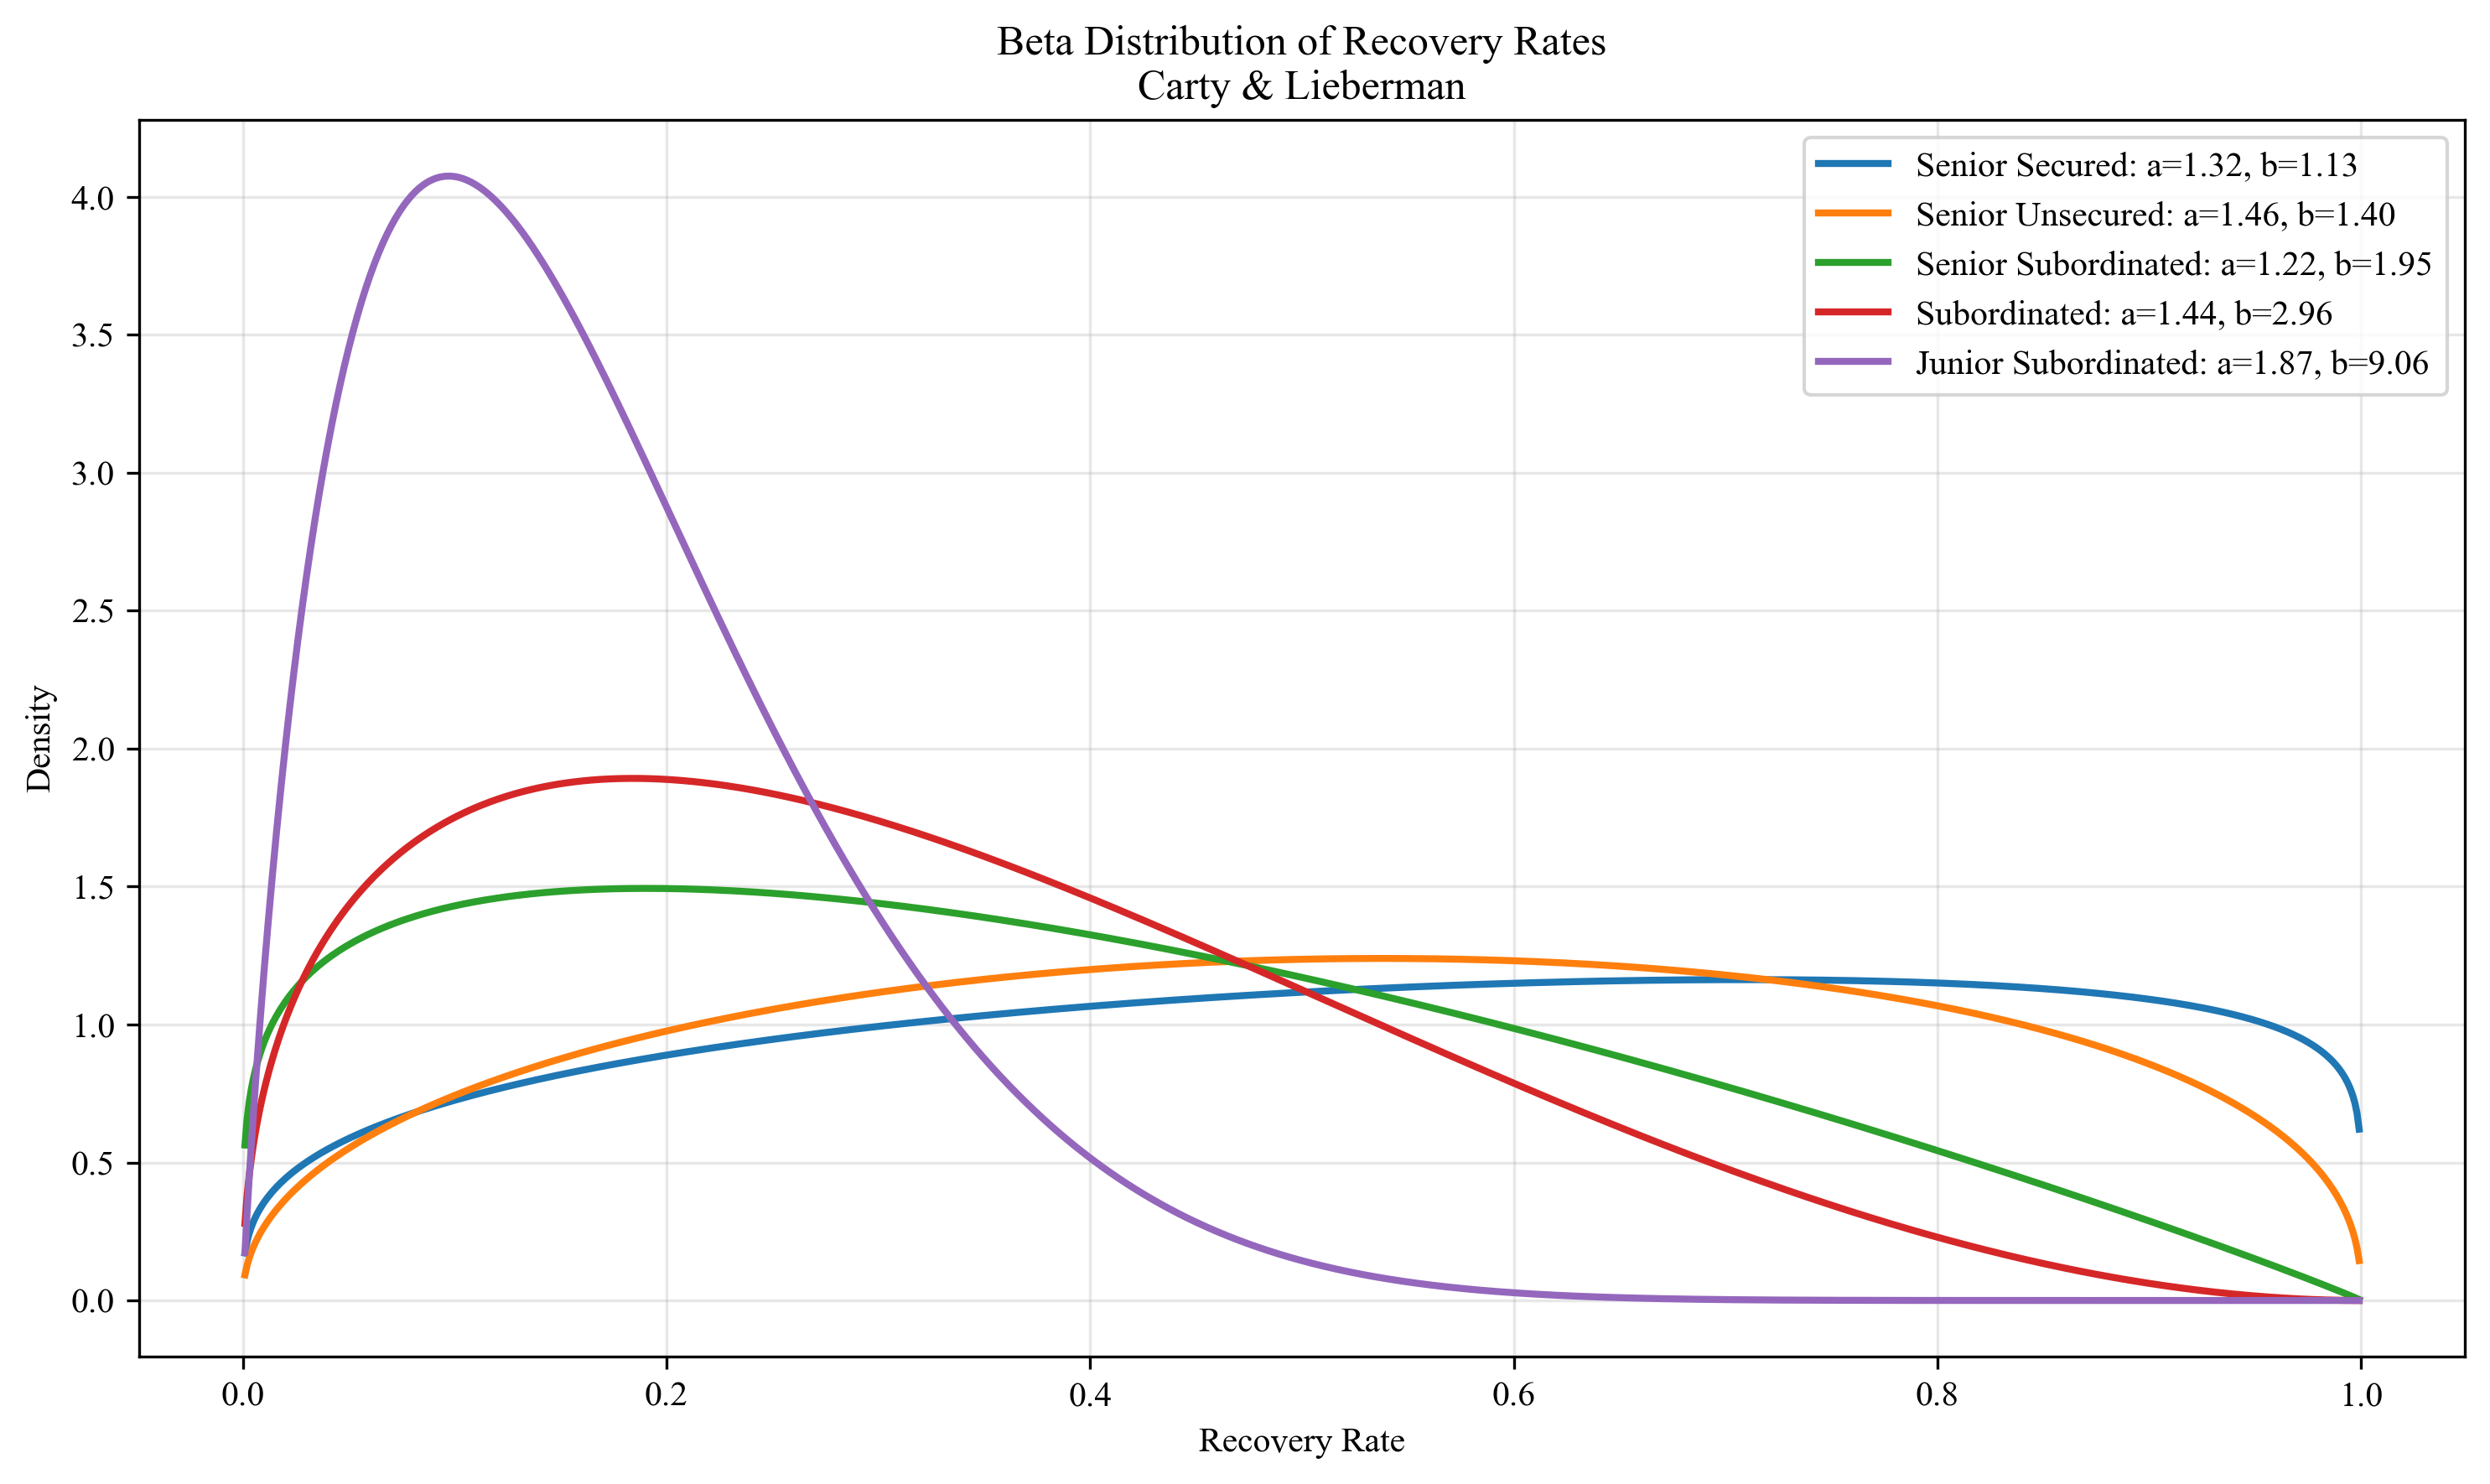

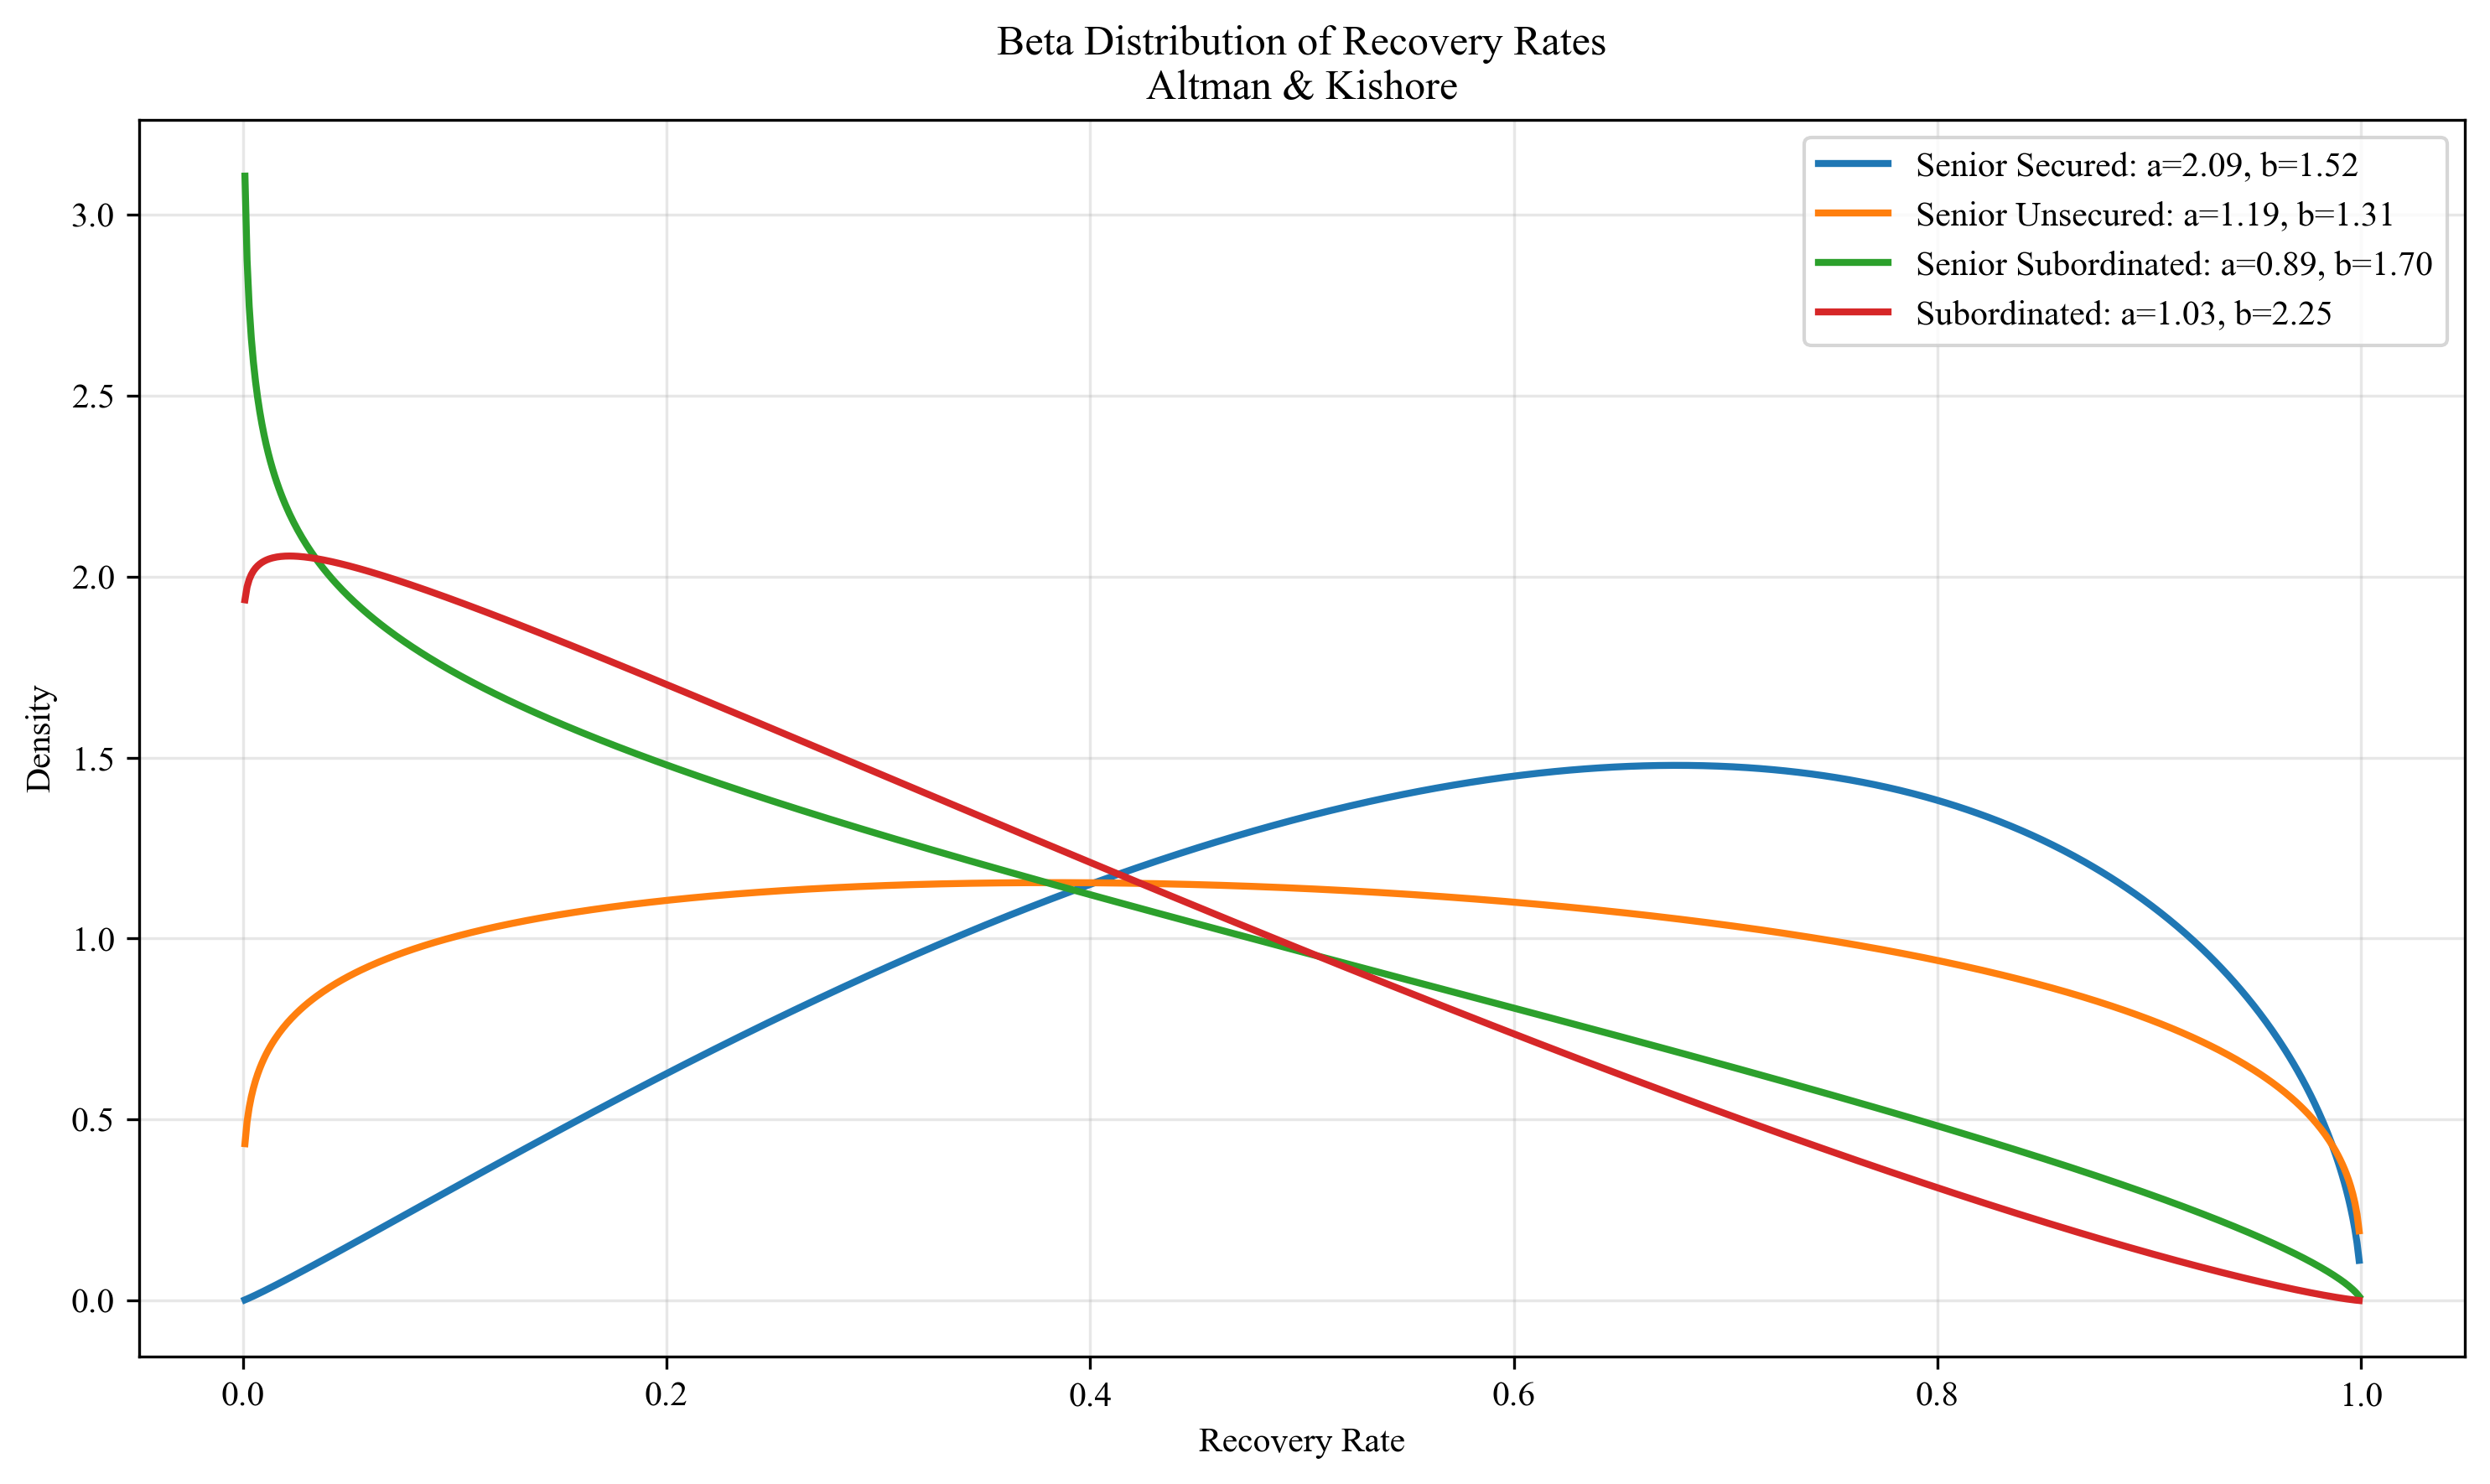

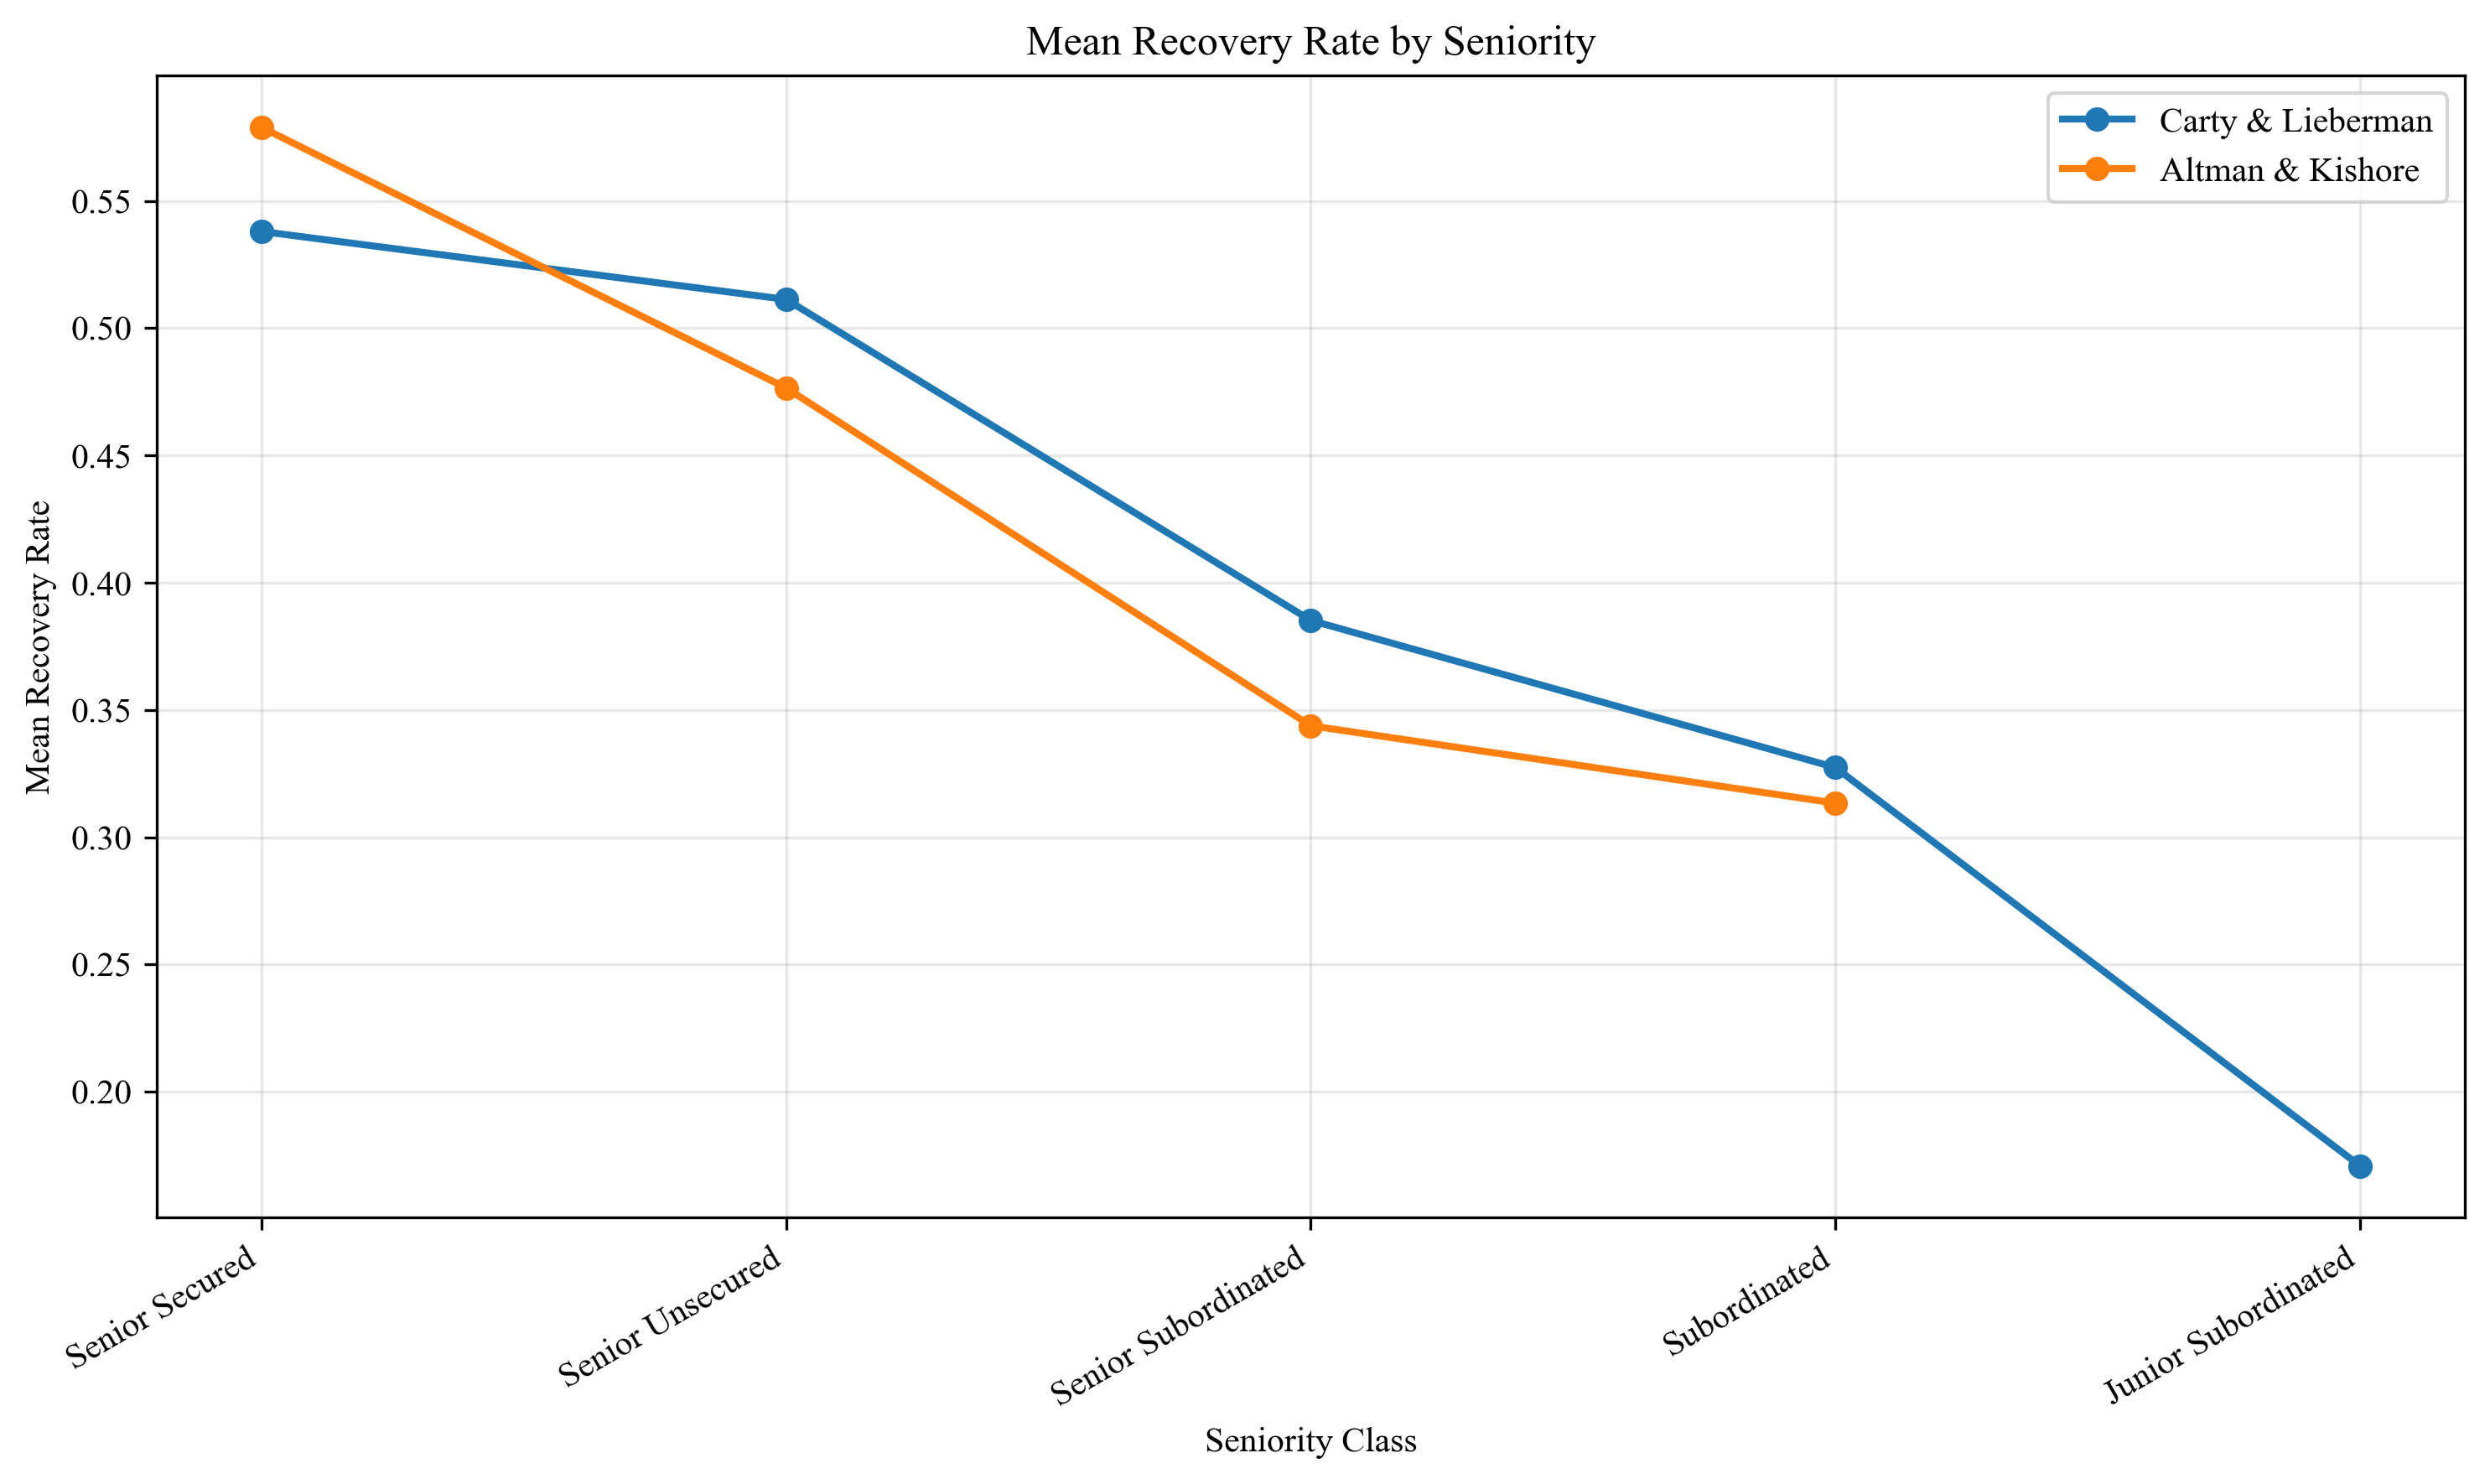

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import beta
plt.rcParams["font.family"] = "Times New Roman"


# ============================================================
# 1. 输入 Table 7.1 数据
# ============================================================

data = [
    # Study, Seniority, Number, Average, Std.Dev.
    ["Carty & Lieberman", "Senior Secured",
     115, 53.80, 26.86],
    ["Carty & Lieberman", "Senior Unsecured",
     278, 51.13, 25.45],
    ["Carty & Lieberman", "Senior Subordinated",
     196, 38.52, 23.81],
    ["Carty & Lieberman", "Subordinated",
     226, 32.74, 20.18],
    ["Carty & Lieberman", "Junior Subordinated",
     9, 17.09, 10.90],
    ["Altman & Kishore", "Senior Secured",
     85, 57.89, 22.99],
    ["Altman & Kishore", "Senior Unsecured",
     221, 47.65, 26.71],
    ["Altman & Kishore", "Senior Subordinated",
     177, 34.38, 25.08],
    ["Altman & Kishore", "Subordinated",
     214, 31.34, 22.42],
]


df = pd.DataFrame(
    data,
    columns=[
        "Study",
        "Seniority",
        "N",
        "Average",
        "Std"
    ]
)


# ============================================================
# 2. 将美元回收额转换为回收率
# ============================================================

df["mean"] = df["Average"] / 100
df["sd"] = df["Std"] / 100

df["var"] = df["sd"] ** 2


# ============================================================
# 3. Beta 分布矩估计
# ============================================================

# kappa = alpha + beta
df["kappa"] = (
    df["mean"] * (1 - df["mean"])
    / df["var"]
    - 1
)

df["alpha"] = (
    df["mean"] * df["kappa"]
)

df["beta"] = (
    (1 - df["mean"]) * df["kappa"]
)


# ============================================================
# 4. 输出估计参数
# ============================================================

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.4f}"
)

print(
    df[
        [
            "Study",
            "Seniority",
            "N",
            "mean",
            "sd",
            "alpha",
            "beta"
        ]
    ]
)


# ============================================================
# 5. Carty & Lieberman Beta 密度曲线
# ============================================================

x = np.linspace(
    0.001,
    0.999,
    1000
)

df_CL = df[
    df["Study"] == "Carty & Lieberman"
]


plt.figure(figsize=(10, 6), dpi=300)

for _, row in df_CL.iterrows():

    y = beta.pdf(
        x,
        row["alpha"],
        row["beta"]
    )

    plt.plot(
        x,
        y,
        linewidth=2,
        label=(
            f'{row["Seniority"]}: '
            f'a={row["alpha"]:.2f}, '
            f'b={row["beta"]:.2f}'
        )
    )


plt.xlabel("Recovery Rate")
plt.ylabel("Density")

plt.title(
    "Beta Distribution of Recovery Rates\n"
    "Carty & Lieberman"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 6. Altman & Kishore Beta 密度曲线
# ============================================================

df_AK = df[
    df["Study"] == "Altman & Kishore"
]


plt.figure(figsize=(10, 6), dpi=300)

for _, row in df_AK.iterrows():

    y = beta.pdf(
        x,
        row["alpha"],
        row["beta"]
    )

    plt.plot(
        x,
        y,
        linewidth=2,
        label=(
            f'{row["Seniority"]}: '
            f'a={row["alpha"]:.2f}, '
            f'b={row["beta"]:.2f}'
        )
    )


plt.xlabel("Recovery Rate")
plt.ylabel("Density")

plt.title(
    "Beta Distribution of Recovery Rates\n"
    "Altman & Kishore"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 7. 比较两个研究的均值
# ============================================================

plt.figure(figsize=(10, 6), dpi=300)

for study in df["Study"].unique():

    subset = df[
        df["Study"] == study
    ]

    plt.plot(
        subset["Seniority"],
        subset["mean"],
        marker="o",
        linewidth=2,
        label=study
    )


plt.ylabel("Mean Recovery Rate")

plt.xlabel("Seniority Class")

plt.title(
    "Mean Recovery Rate by Seniority"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

# (二) 信用等级联合概率

In [7]:
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.stats import norm


# ============================================================
# 0. 基本设置
# ============================================================

ratings = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "D"]

# 顺序: AAA, AA, A, BBB, BB, B, CCC, D
p_A = np.array([0.09, 2.27, 91.05, 5.52, 0.74, 0.26, 0.01, 0.06]) / 100
p_BB = np.array([0.03, 0.14, 0.67, 7.73, 80.53, 8.84, 1.00, 1.06]) / 100

assert np.isclose(p_A.sum(), 1.0)
assert np.isclose(p_BB.sum(), 1.0)

rho = 0.5


# ============================================================
# 1. 阈值: 升序, 从最坏状态往最好状态累加
# ============================================================

def get_thresholds(p):
    """
    p: [AAA, AA, ..., D]  (原顺序)

    从 D 开始往上累积:
        cum[0] = P(D)
        cum[1] = P(D or CCC)
        ...
        cum[6] = P(<= AA) = 1 - P(AAA)

    z[k] = 状态 k 与状态 k+1 之间的分界点 (k 按 ratings 原顺序)
         且 z 严格单调递增: z[0] < z[1] < ... < z[6]

    评级区间:
        AAA : (z[6], +inf)
        AA  : (z[5], z[6])
        A   : (z[4], z[5])
        BBB : (z[3], z[4])
        BB  : (z[2], z[3])
        B   : (z[1], z[2])
        CCC : (z[0], z[1])
        D   : (-inf, z[0])
    """
    cum = np.cumsum(p[::-1])          # 从 D 到 AAA 累积
    z = norm.ppf(cum[:-1])            # 去掉最后一个 1.0
    return z                          # 升序


def make_intervals(p):
    """返回 (lower[8], upper[8]), 索引与 ratings 一致"""
    z = get_thresholds(p)             # 升序 z[0] < ... < z[6]
    lower = np.empty(8)
    upper = np.empty(8)

    lower[0], upper[0] = z[6], np.inf          # AAA
    for k in range(1, 7):                      # AA ... CCC
        lower[k] = z[6 - k]
        upper[k] = z[7 - k]
    lower[7], upper[7] = -np.inf, z[0]         # D

    return lower, upper


lower_A,  upper_A  = make_intervals(p_A)
lower_BB, upper_BB = make_intervals(p_BB)

# 自检: 单变量区间积分应精确还原原转移概率
for i, r in enumerate(ratings):
    assert np.isclose(
        norm.cdf(upper_A[i]) - norm.cdf(lower_A[i]),
        p_A[i], atol=1e-9
    ), r

print("阈值 (升序, 从 D/CCC 界到 AA/AAA 界):")
print(np.round(get_thresholds(p_A), 4))
print(np.round(get_thresholds(p_BB), 4))


# ============================================================
# 2. 二元正态矩形概率: conditional normal + quad
# ============================================================

def bv_rect(l1, u1, l2, u2, rho):
    """
    P( l1 < X < u1 , l2 < Y < u2 ),
    (X, Y) ~ BVN(0, 0, 1, 1, rho)
    """
    if u1 <= l1 or u2 <= l2:
        return 0.0

    rho2 = rho ** 2
    if rho2 < 1e-12:                 # 近似独立, 避免除零
        return (norm.cdf(u1) - norm.cdf(l1)) * (norm.cdf(u2) - norm.cdf(l2))

    sd = np.sqrt(1.0 - rho2)

    def integrand(x):
        a = (l2 - rho * x) / sd
        b = (u2 - rho * x) / sd
        return (norm.cdf(b) - norm.cdf(a)) * norm.pdf(x)

    val, err = quad(integrand, l1, u1, epsabs=1e-13, limit=200)
    return val


# ============================================================
# 3. 8 x 8 联合转移概率
# ============================================================

joint = np.zeros((8, 8))

for i in range(8):
    for j in range(8):
        joint[i, j] = bv_rect(
            lower_A[i],  upper_A[i],
            lower_BB[j], upper_BB[j],
            rho,
        )


# ============================================================
# 4. 结果表 (%)
# ============================================================

joint_tbl = pd.DataFrame(
    joint * 100,
    index=ratings,
    columns=ratings,
)

joint_tbl.index.name = "公司1 (现A) \\ 公司2 (现BB)"
joint_tbl.columns.name = "公司2 (现BB)"

pd.set_option("display.float_format", "{:.5f}".format)
pd.set_option("display.width", 200)

print("\n联合转移概率 (%)\n")
print(joint_tbl)


# ============================================================
# 5. 边缘校验 (应分别还原 p_A, p_BB)
# ============================================================

print("\n行和 vs A 单边概率:")
print((joint_tbl.sum(axis=1).values - p_A * 100).round(6))

print("\n列和 vs BB 单边概率:")
print((joint_tbl.sum(axis=0).values - p_BB * 100).round(6))

print(f"\n总概率 = {joint.sum():.10f}")

阈值 (升序, 从 D/CCC 界到 AA/AAA 界):
[-3.2389 -3.1947 -2.7164 -2.3009 -1.507   1.9845  3.1214]
[-2.3044 -2.0415 -1.2319  1.3677  2.3911  2.929   3.4316]

联合转移概率 (%)

公司2 (现BB)                AAA      AA       A     BBB       BB       B     CCC       D
公司1 (现A) \ 公司2 (现BB)                                                                 
AAA                  0.00216 0.00504 0.01208 0.03893  0.03176 0.00004 0.00000 0.00000
AA                   0.01091 0.03862 0.13212 0.73945  1.34175 0.00687 0.00020 0.00009
A                    0.01693 0.09631 0.52538 6.92555 75.12379 7.05503 0.68855 0.61846
BBB                  0.00000 0.00003 0.00040 0.02492  3.54149 1.42120 0.23169 0.30027
BB                   0.00000 0.00000 0.00001 0.00099  0.36737 0.24073 0.05000 0.08090
B                    0.00000 0.00000 0.00000 0.00015  0.10399 0.09134 0.02219 0.04233
CCC                  0.00000 0.00000 0.00000 0.00000  0.00332 0.00360 0.00098 0.00211
D                    0.00000 0.00000 0.00000 0.00001  0.01654 0.021